<a href="https://colab.research.google.com/github/oq7oq/Alphasia-project/blob/main/03_multimodal_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Phase 4: Multimodal Data Fusion and Correlation Analysis

**Objective:**
To integrate linguistic features (derived from transcripts) and acoustic features (derived from audio signals) into a unified multimodal dataset, and to compute statistical correlations between these distinct biomarker modalities.

**Methodology:**
1. **Data Fusion:** Utilizing `pandas` to perform an inner join on the Patient ID, merging the `patient_features.csv` and `audio_features.csv` datasets.
2. **Correlation Matrix:** Computing the Pearson correlation coefficient across all quantitative variables to identify multi-domain relationships (e.g., the relationship between semantic hesitation ratios and acoustic speech duration).
3. **Visualization:** Generating a heatmap visualization using `seaborn` to intuitively represent the strength and direction of these correlations, providing exploratory insights critical for feature selection in future machine learning models.

[Process] Mounting Google Drive...
Mounted at /content/drive

[Process] Loading linguistic and acoustic datasets...
[Success] Data fusion complete. Merged dataset saved to: /content/drive/MyDrive/aphasia-ecosystem/multimodal_features.csv
[Info] Total multimodal records: 11
------------------------------------------------------------
[Process] Generating correlation matrix...


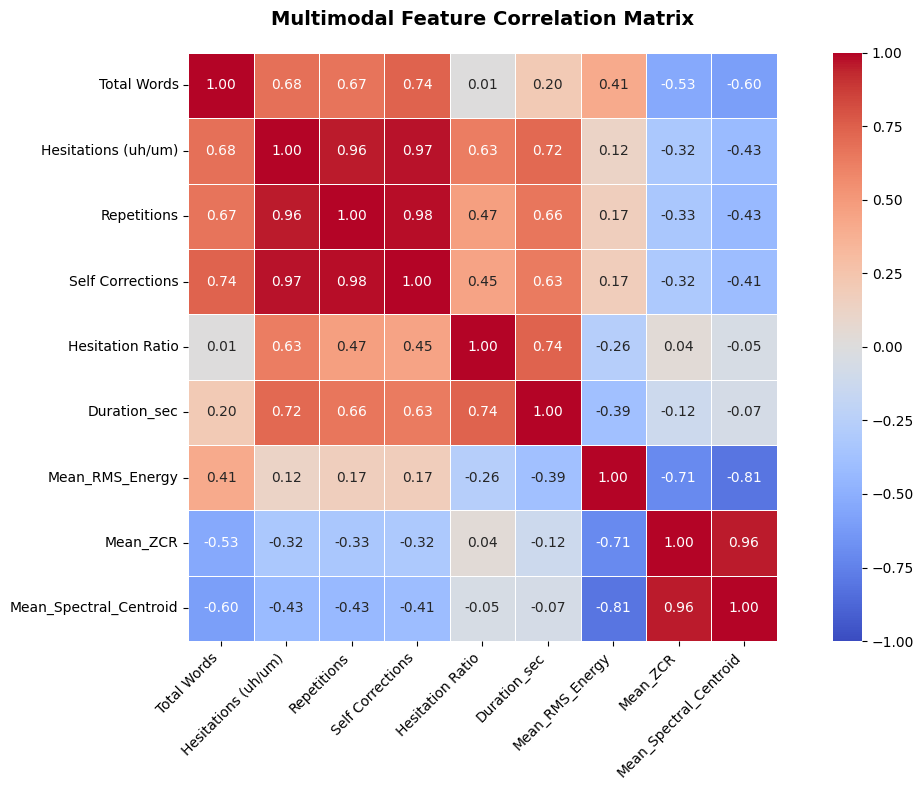

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

print("[Process] Mounting Google Drive...")
drive.mount('/content/drive')

# ==========================================
# 2. Data Fusion Configuration
# ==========================================
data_dir = Path("/content/drive/MyDrive/aphasia-ecosystem")
linguistic_csv = data_dir / "patient_features.csv"
acoustic_csv = data_dir / "audio_features.csv"
multimodal_csv = data_dir / "multimodal_features.csv"

print("\n[Process] Loading linguistic and acoustic datasets...")

try:
    # Load datasets
    df_linguistic = pd.read_csv(linguistic_csv)
    df_acoustic = pd.read_csv(acoustic_csv)

    # Merge datasets on Patient_ID
    # Standardizing column type to ensure perfect matching
    df_linguistic['Patient_ID'] = df_linguistic['Patient_ID'].astype(str)
    df_acoustic['Patient_ID'] = df_acoustic['Patient_ID'].astype(str)

    df_merged = pd.merge(df_linguistic, df_acoustic, on="Patient_ID", how="inner")

    # Export merged dataset
    df_merged.to_csv(multimodal_csv, index=False)
    print(f"[Success] Data fusion complete. Merged dataset saved to: {multimodal_csv}")
    print(f"[Info] Total multimodal records: {len(df_merged)}")
    print("-" * 60)

    # ==========================================
    # 3. Correlation Analysis & Visualization
    # ==========================================
    print("[Process] Generating correlation matrix...")

    # Drop non-numeric columns for correlation calculation
    df_numeric = df_merged.drop(columns=['Patient_ID'])

    # Calculate Pearson correlation
    corr_matrix = df_numeric.corr()

    # Set up the matplotlib figure
    plt.figure(figsize=(12, 8))

    # Generate a custom diverging colormap and plot the heatmap
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, square=True, linewidths=.5)

    plt.title("Multimodal Feature Correlation Matrix", fontsize=14, fontweight='bold', pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"\n[Error] Pipeline failed. Details: {e}")